# **Tasks:**
1. Upload the file gc
2. Import pandas
3. Load the dataset
4. Display last five rows
5. Display last five rows
6. Display the information
7. Describe the summary statistics
8. Identify the missing values.

In [39]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.900,0.0,yes,southwest,16884.92400
1,18.0,male,33.770,1.0,no,southeast,1725.55230
2,28.0,male,33.000,3.0,no,southeast,4449.46200
3,33.0,male,22.705,0.0,no,northwest,21984.47061
4,32.0,male,28.880,0.0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50.0,male,30.970,3.0,no,northwest,10600.54830
1334,18.0,female,31.920,0.0,no,northeast,2205.98080
1335,18.0,female,36.850,0.0,no,southeast,1629.83350
1336,21.0,female,25.800,0.0,no,southwest,2007.94500


In [40]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.900,0.0,yes,southwest,16884.92400
1,18.0,male,33.770,1.0,no,southeast,1725.55230
2,28.0,male,33.000,3.0,no,southeast,4449.46200
3,33.0,male,22.705,0.0,no,northwest,21984.47061
4,32.0,male,28.880,0.0,no,northwest,3866.85520


In [42]:
df.tail(5)

,age,sex,bmi,children,smoker,region,charges
1333,50.0,male,30.97,3.0,no,northwest,10600.5483
1334,18.0,female,31.92,0.0,no,northeast,2205.9808
1335,18.0,female,36.85,0.0,no,southeast,1629.8335
1336,21.0,female,25.80,0.0,no,southwest,2007.9450
1337,61.0,female,29.07,0.0,yes,northwest,29141.3603


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1335 non-null   float64
 1   sex       1336 non-null   object 
 2   bmi       1335 non-null   float64
 3   children  1336 non-null   float64
 4   smoker    1336 non-null   object 
 5   region    1336 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(4), object(3)
memory usage: 73.3+ KB


In [44]:
df.shape

(1338, 7)

In [45]:
df.dtypes

,0
age,float64
sex,object
bmi,float64
children,float64
smoker,object
region,object
charges,float64


In [46]:
df.describe()

,age,bmi,children,charges
count,1335.000000,1335.000000,1336.000000,1337.000000
mean,39.238951,30.657903,1.096557,13271.853650
std,14.047648,6.101257,1.205650,12114.429349
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.255000,0.000000,4738.268200
50%,39.000000,30.400000,1.000000,9377.904700
75%,51.000000,34.637500,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [47]:
df.isnull().sum()

,0
age,3
sex,2
bmi,3
children,2
smoker,2
region,2
charges,1


In [48]:
insurance_input_colums = ["age", "sex", "bmi", "children", "smoker", "region"]
insurance_target_colums = "charges"
print("Input variables :",insurance_input_colums)
print("Target variable :",insurance_target_colums)

Input variables : ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target variable : charges


In [49]:
#Cheak duplicate rows
df.duplicated().sum()

np.int64(1)

In [50]:
#Remove duplicate rows
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

# **Checking Skewness (Imputation Rule)**

* **Skewness between $-0.5$ and $0.5$**: Use **mean**.


* **Skewness less than $-0.5$ or greater than $0.5$**: Use **median**.


* **Categorical column**: Use **mode**.

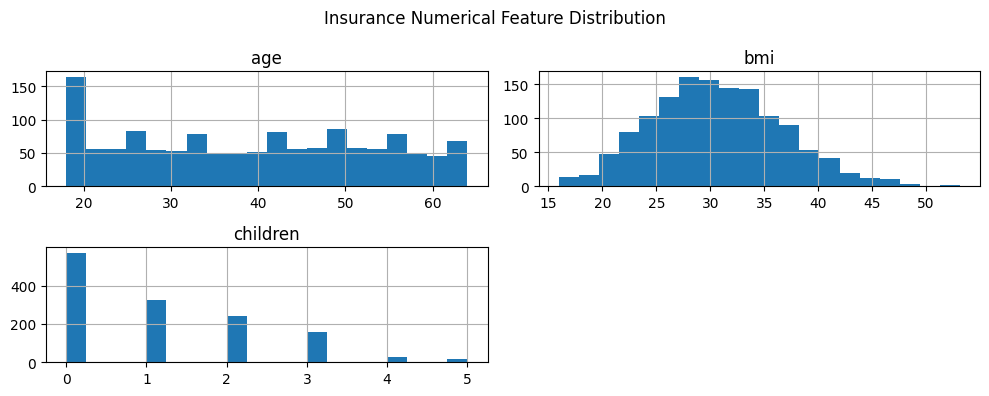

In [51]:
import matplotlib.pyplot as plt

insurance_numerical_colums = ["age", "bmi", "children"]
df[insurance_numerical_colums].hist(
    bins=20,
    figsize=(10,4)
)
plt.suptitle("Insurance Numerical Feature Distribution")
plt.tight_layout()
plt.show()

In [52]:
df[insurance_numerical_colums].skew()

,0
age,0.051264
bmi,0.286014
children,0.935500


In [53]:
for column in insurance_numerical_colums:
  skew_value = df[column].skew()
  if skew_value > 0.5:
    print(column,"-> Use mean")
  else:
    print(column,"-> Use median")

age -> Use median
bmi -> Use median
children -> Use mean


In [54]:
df["age"] = df["age"].fillna(df["age"].mean())
df["bmi"] = df["bmi"].fillna(df["bmi"].mean())
df["children"] = df["children"].fillna(df["children"].median())

/tmp/ipykernel_6160/2719152656.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["age"] = df["age"].fillna(df["age"].mean())
/tmp/ipykernel_6160/2719152656.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["bmi"] = df["bmi"].fillna(df["bmi"].mean())
/tmp/ipykernel_6160/2719152656.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pa

In [55]:
df.isnull().sum()

,0
age,0
sex,2
bmi,0
children,0
smoker,2
region,2
charges,1


In [56]:
df['sex'] = df['sex'].fillna(df['sex'].mode()[0])
df['smoker'] = df['smoker'].fillna(df['smoker'].mode()[0])
df['region'] = df['region'].fillna(df['region'].mode()[0])

/tmp/ipykernel_6160/2662180201.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sex'] = df['sex'].fillna(df['sex'].mode()[0])
/tmp/ipykernel_6160/2662180201.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['smoker'] = df['smoker'].fillna(df['smoker'].mode()[0])
/tmp/ipykernel_6160/2662180201.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://panda

In [57]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,1


In [58]:
df = df.dropna(subset=['charges'])
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [59]:
df.shape

(1336, 7)

In [60]:
insurance_encoded=pd.get_dummies(df,columns=["sex","smoker","region"],dtype=int)
insurance_encoded.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,16884.92400,1,0,0,1,0,0,0,1
1,18.0,33.770,1.0,1725.55230,0,1,1,0,0,0,1,0
2,28.0,33.000,3.0,4449.46200,0,1,1,0,0,0,1,0
3,33.0,22.705,0.0,21984.47061,0,1,1,0,0,1,0,0
4,32.0,28.880,0.0,3866.85520,0,1,1,0,0,1,0,0


In [61]:
x_insurance = insurance_encoded.drop("charges",axis=1)
y_insurance = insurance_encoded["charges"]
print("Input shape :",x_insurance.shape)
print("Target shape :",y_insurance.shape)

Input shape : (1336, 11)
Target shape : (1336,)


**Feature Scaling**

* **Definition**: A method to rescale feature values, converting different measurement scales into a single scale and standardizing the dataset into one range.


* **Standard Scaler (Standardization)**:
* Scales features based on the standard normal distribution so that the mean is $0$ and the standard deviation is $1$, bringing all features to the same magnitude.


* **Formula**: $Z = \frac{x - \mu}{\sigma}$ (where $x$ = score, $\mu$ = mean, $\sigma$ = standard deviation).




* **Min-Max Scaler (Normalization)**:
* Normalization help in Scales features down to a range between $0$ and $1$.


* **Formula**: $X_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$.

(In ML we call colums as feature)

# **DATA IMBALANCE**
* Balanced Data
* Inbalanced Data

## **Handling Data Imbalance**
* Undersampling
* Oversampling

# **Feature Encoding**

1. **One-hot encoding**: Creates a separate column for each category, marking the present category with `1` and all others with `0`.


2. **Dummy encoding**: Drops one feature (column) randomly from one-hot encoding, representing the dropped category with a row of all `0`s.


3. **Effect encoding**: Similar to dummy encoding, but sets the values of the row with all zeros to `-1`.


4. **Label encoding**: Assigns a unique numerical label to each category (e.g., Green = 1, Red = 2, Black = 3).


5. **Ordinal encoding**: Assigns unique numerical labels to ordered categories based on their rank (e.g., XS = 1, S = 2, M = 3, L = 4).


6. **Count encoding**: Encodes each category based on its frequency (number of occurrences) in the dataset.


7. **Binary encoding**: Converts categories into binary labels across multiple columns (e.g., `0` and `1` combinations).

# **Data Splitting**

* **Initial Split (Available Data)**: Divided into **Training** and **Testing (holdout sample)**.


* **Second Split (New Available Data)**: The initial training portion becomes the **New Available Data** and is further split into **Training** and **Validation (validation holdout sample)**, while **Testing (testing holdout sample)** remains separate.

# **Challenges Before Machine Learning**



* Rule-based systems fail in real-life scenarios.


* Hand-coding systems is difficult.


* Programs fail outside of test scenarios.



## **Machine Learning Timeline**



* **1950**: Turing Machine


* **1997**: Gary Kasparov vs. IBM Deep Blue


* **2010**: Microsoft Kinect Gesture Recognition


* **2014**: Face Recognition in Facebook


* **2016**: Google's AlphaGo



### **Machine Learning Benefits**



* Analyzing complex big data


* Powerful processing


* Better decision-making and prediction


* Quicker processing


* Affordable data management


* Inexpensive



### **What is Machine Learning?**



* **Definition**: The science of making computers learn and act like humans by feeding them data and information without being explicitly programmed.


* **How it Works**: The system analyzes and trains/learns from **Past Data** to make a **Decision or Prediction (Output)**.


* **Key Characteristics**:
* Computers imitate and adapt to human-like behavior.


* Makes predictions and decisions based on past data.


* Systems learn, grow, and develop when exposed to new data.





### **Processes Involved in Machine Learning (7 Steps)**



1. **Data Gathering**


2. **Data Pre-Processing**


3. **Choose Model**


4. **Train Model**


5. **Test Model**


6. **Tune Model**


7. **Prediction**

# Types of Machine Learning



* **Supervised Learning**: A machine learning model predicts future outcomes using training from past data.


* **Unsupervised Learning**: Finds hidden patterns without any external input other than the raw data.


* **Reinforcement Learning**: The system takes decisions based on past rewards for its actions.

# Machine Learning Algorithms



* **Supervised Machine Learning**:


* Classification


* Regression




* **Unsupervised Machine Learning**:


* Clustering


* Association

# **Supervised Machine Learning - Classification**

* **Definition**: Enables the machine to be trained to classify observations into specific classes.


* **How it Works**: The model learns from labeled **Past Data** (e.g., sorted into categories) and uses that training to sort **New Data** into the appropriate **Predicted Output** classes.


* **Example**: Email filtering (classifying incoming mail as normal or spam).

# **Supervised Machine Learning - Regression**

* **Definition**: The system tries to predict a value for an input based on previous information.


* **How it Works**: The model **learns** from **Past data** and uses that training to predict an output when given **New data**.


* **Example**: Weather forecasting (using past conditions like temperature, wind, and clouds to predict rainfall).

# **Types of Regression**

1. Linear Regression
2. Multi linear Regression
3. Polynomial Regression
4. Lasso Regression
5. Ridge Regression

# **Linear Regression**

* **Definition**: A linear modeling approach to find the relationship between one or more independent variables (predictors, denoted as **$X$**) and a dependent variable (target, denoted as **$Y$**).


* **Example**: Predicting ice cream sales ($Y$) based on temperature ($X$).


* **Finding the Best Fit Line**: Found by minimizing the distance between all data points and the regression line.


* **Methods to Minimize Distance**: Sum of squared errors, sum of absolute errors, etc..


* **Not the Best Fit Line**: When the distance between the data points and the line is at a maximum.

Scikit learn - it is ml library

In [62]:
from sklearn.model_selection import train_test_split


x_train_insurance, x_test_insurance, y_train_insurance, y_test_insurance = train_test_split(
    x_insurance,
    y_insurance,
    train_size=0.8,
    test_size=0.20,
    random_state=42
)
print("Training rows:",x_train_insurance.shape[0])
print("Testing rows:",x_test_insurance.shape[0])

Training rows: 1068
Testing rows: 268


In [63]:
from sklearn.preprocessing import StandardScaler

insurance_scaler = StandardScaler()
scale_columns = ["age", "bmi", "children"]

x_train_insurance_scaled = x_train_insurance.copy()
x_test_insurance_scaled = x_test_insurance.copy()

x_train_insurance_scaled[scale_columns] = insurance_scaler.fit_transform(x_train_insurance[scale_columns])
x_test_insurance_scaled[scale_columns] = insurance_scaler.transform(x_test_insurance[scale_columns])

In [64]:
x_train_insurance_scaled

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
1114,-1.162538,-1.016075,-0.924494,0,1,1,0,1,0,0,0
968,-1.306018,-0.811850,0.754689,0,1,1,0,1,0,0,0
600,-1.521239,1.406511,-0.924494,1,0,1,0,0,0,1,0
171,0.702707,-0.058616,-0.924494,0,1,1,0,0,0,0,1
276,-1.449499,-1.660168,0.754689,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
1097,-1.234278,0.515198,-0.924494,0,1,1,0,0,0,1,0
1132,1.276629,1.591719,-0.924494,0,1,1,0,1,0,0,0
1296,-1.521239,-0.749011,-0.924494,0,1,1,0,1,0,0,0
862,1.133148,0.476337,0.754689,1,0,1,0,0,1,0,0


In [65]:
x_test_insurance_scaled

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
900,0.702707,-1.345976,-0.924494,0,1,1,0,1,0,0,0
1064,-0.732097,-0.835828,2.433872,1,0,1,0,0,0,0,1
1256,0.846188,0.947625,1.594281,1,0,1,0,0,1,0,0
299,0.630967,-0.293433,-0.084903,1,0,1,0,0,1,0,0
238,-1.449499,-0.262014,-0.924494,0,1,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
535,-0.086435,-0.434819,-0.084903,0,1,1,0,1,0,0,0
543,1.061408,2.770765,-0.924494,1,0,0,1,0,0,1,0
897,-1.449499,-0.843269,-0.084903,0,1,1,0,0,1,0,0
1094,0.774447,0.503622,2.433872,1,0,1,0,0,0,0,1


In [66]:
#Import and create Linear Regression model
from sklearn.linear_model import LinearRegression
linear_model= LinearRegression()

In [67]:
from sklearn.linear_model import Lasso
linear_modelLR = Lasso()

## **Train the model**

In [68]:
linear_model.fit(x_train_insurance_scaled,y_train_insurance)
print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


## **Predict Test Data**

In [69]:
pred = linear_model.predict(x_test_insurance_scaled)

## **Compare actual and predicted values**

In [70]:
insurance_result = pd.DataFrame({"Actual":y_test_insurance,"Predicted":pred})
insurance_result.tail()

,Actual,Predicted
535,6067.12675,7876.367735
543,63770.42801,40351.308028
897,2221.56445,1736.775194
1094,11299.34300,13480.803187
1285,8534.67180,8379.170552


Metrics


Regression Metrics
1. RMSE - Root Mean Squared Error


In [71]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test_insurance,pred)
mse = mean_squared_error(y_test_insurance,pred)
rmse = mse ** 0.5
r2 = r2_score(y_test_insurance,pred)

print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2:",r2)

MAE: 4331.875132152566
MSE: 40197109.01046901
RMSE: 6340.119006017869
R2: 0.7346743443721404


In [72]:
new_customer = pd.DataFrame({"age":[35],"sex":["male"],"bmi":[27.5],"children":[2],"smoker":["no"],"region":["southeast"]})
new_customer

,age,sex,bmi,children,smoker,region
0,35,male,27.5,2,no,southeast


In [73]:
new_customer_encoded = pd.get_dummies(new_customer,columns=["sex","smoker","region"],dtype=int)
new_customer_encoded

,age,bmi,children,sex_male,smoker_no,region_southeast
0,35,27.5,2,1,1,1


In [74]:
new_customer_scaled = new_customer_encoded.copy()
new_customer_scaled[scale_columns] = insurance_scaler.transform(new_customer_scaled[scale_columns])
new_customer_scaled

,age,bmi,children,sex_male,smoker_no,region_southeast
0,-0.301656,-0.521636,0.754689,1,1,1


In [75]:
new_customer_aligned = new_customer_scaled.reindex(columns=x_train_insurance_scaled.columns, fill_value=0)
unkown_charges_prediction = linear_model.predict(new_customer_aligned)[0]
print("Predicted insurance charges:", unkown_charges_prediction)

Predicted insurance charges: 6439.495468281702


In [76]:
import joblib
joblib.dump(linear_model,"model.pkl")

['model.pkl']

# **Classification Types**



1. Decision Tree

2. Random Forest

3. Logistic Regression

4. KNN (K-Nearest Neighbour)

5. Support Vector Machine

6. Naive Bayes

7. Gradient Boosting Classifier

# **Decision Trees: Choosing the Right Split**

To determine the best split in a decision tree, we calculate **Entropy** and **Information Gain**:

* **Entropy:**
* Measures the randomness or *impurity* in a dataset.
* **Goal:** Should be **low**.


* **Information Gain (Entropy Reduction):**
* Measures the decrease in entropy after the dataset is split.
* **Goal:** Should be **high**.

**Entropy Formula**

$$\text{Entropy} = I(p, n) = -\frac{p}{p+n} \times \log_2\left(\frac{p}{p+n}\right) - \frac{n}{p+n} \times \log_2\left(\frac{n}{p+n}\right)$$



* **$p$:** Number of positive class examples
* **$n$:** Number of negative class examples
* **$p + n$:** Total number of examples
* **Range:** $0$ (completely pure) to $1$ (maximum impurity / 50–50 split)